In [16]:
# 1)
import pandas as pd
import numpy as np

In [17]:
df = pd.read_csv("social_media_engagement_5000.csv")

df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,17-12-2022,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,02-06-2023,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,07-05-2023,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,12-02-2023,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,23-05-2023,383936,False,mobile,negative,#travel,2.777372


In [18]:
df.dtypes

user_id               int64
age                 float64
gender                  str
country                 str
post_id               int64
post_type               str
post_category           str
likes               float64
comments            float64
shares              float64
watch_time_sec        int64
impression_count      int64
posted_at               str
follower_count        int64
is_verified            bool
device_type             str
sentiment               str
hashtags                str
engagement_rate     float64
dtype: object

In [19]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   user_id           5000 non-null   int64  
 1   age               4850 non-null   float64
 2   gender            4850 non-null   str    
 3   country           5000 non-null   str    
 4   post_id           5000 non-null   int64  
 5   post_type         5000 non-null   str    
 6   post_category     5000 non-null   str    
 7   likes             4850 non-null   float64
 8   comments          4850 non-null   float64
 9   shares            4850 non-null   float64
 10  watch_time_sec    5000 non-null   int64  
 11  impression_count  5000 non-null   int64  
 12  posted_at         5000 non-null   str    
 13  follower_count    5000 non-null   int64  
 14  is_verified       5000 non-null   bool   
 15  device_type       5000 non-null   str    
 16  sentiment         4850 non-null   str    
 17  hashta

In [20]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate'],
      dtype='str')

In [21]:
df["posted_at"] = pd.to_datetime(df["posted_at"])

C:\Users\user\AppData\Local\Temp\ipykernel_9616\1371919733.py:1: UserWarning: Parsing dates in %d-%m-%Y format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df["posted_at"] = pd.to_datetime(df["posted_at"])


In [22]:
likes = df["likes"].to_numpy()

print("Total Likes:", np.sum(likes))
print("Average Likes:", np.mean(likes))
print("Maximum Likes:", np.max(likes))
print("Minimum Likes:", np.min(likes))

Total Likes: nan
Average Likes: nan
Maximum Likes: nan
Minimum Likes: nan


In [23]:
# 2)
df.isnull().sum()

user_id               0
age                 150
gender              150
country               0
post_id               0
post_type             0
post_category         0
likes               150
comments            150
shares              150
watch_time_sec        0
impression_count      0
posted_at             0
follower_count        0
is_verified           0
device_type           0
sentiment           150
hashtags              0
engagement_rate       0
dtype: int64

In [24]:
df.dropna(inplace=True)

In [25]:
df["likes"] = df["likes"].fillna(df["likes"].median())

df["comments"] = df["comments"].fillna(df["comments"].median())

df["shares"] = df["shares"].fillna(df["shares"].median())

In [26]:
df["gender"] = df["gender"].fillna(df["gender"].mode()[0])

In [27]:
df = df.ffill()

In [28]:
df = df.bfill()

In [29]:
df.duplicated().sum()
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate
0,25795,43.0,Female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862
1,10860,33.0,Male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493
2,86820,32.0,Female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345
3,64886,51.0,Other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195
4,16265,34.0,Other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,19018,54.0,Male,India,613622,image,tech,14677.0,2948.0,1176.0,5418,17003,2023-05-01,85261,False,desktop,neutral,#fashion,1.105746
4995,59500,44.0,Male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761
4996,22100,38.0,Other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155
4998,29800,13.0,Female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518


In [30]:
df.drop_duplicates(inplace=True)

In [31]:
df.dtypes

user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
dtype: object

In [32]:
df["posted_at"] = pd.to_datetime(df["posted_at"], errors="coerce")

In [33]:
df["gender"] = df["gender"].str.strip().str.lower()

df["gender"] = df["gender"].replace({
    "m": "male",
    "f": "female"
})

In [34]:
df = df[
    (df["likes"] >= 0) &
    (df["comments"] >= 0) &
    (df["shares"] >= 0)
]

In [35]:
df["hashtag_count"] = df["hashtags"].fillna("").apply(
    lambda x: len(x.split())
)
df

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4994,19018,54.0,male,India,613622,image,tech,14677.0,2948.0,1176.0,5418,17003,2023-05-01,85261,False,desktop,neutral,#fashion,1.105746,1
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3


In [36]:
df["hashtag_count"] = df["hashtags"].fillna("").apply(
    lambda x: len(x.split())
)

In [37]:
# 3)
df.head()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
0,25795,43.0,female,Brazil,496713,image,fitness,7011.0,354.0,1157.0,5726,44650,2022-12-17,81734,False,mobile,negative,#foodie #travel #love,0.190862,3
1,10860,33.0,male,Brazil,157326,reel,food,11750.0,2606.0,1807.0,5947,80216,2023-06-02,5963,False,mobile,negative,#fitness,0.201493,1
2,86820,32.0,female,UK,109864,text,food,4862.0,344.0,955.0,6946,44858,2023-05-07,501783,False,tablet,positive,#foodie,0.137345,1
3,64886,51.0,other,France,848877,text,fitness,5350.0,1083.0,1049.0,229,70455,2023-02-12,480212,False,mobile,negative,#music #foodie #fun,0.106195,3
4,16265,34.0,other,UK,449706,image,fitness,12682.0,2735.0,1300.0,4798,6019,2023-05-23,383936,False,mobile,negative,#travel,2.777372,1


In [38]:
df.tail()

,user_id,age,gender,country,post_id,post_type,post_category,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,is_verified,device_type,sentiment,hashtags,engagement_rate,hashtag_count
4994,19018,54.0,male,India,613622,image,tech,14677.0,2948.0,1176.0,5418,17003,2023-05-01,85261,False,desktop,neutral,#fashion,1.105746,1
4995,59500,44.0,male,Australia,441541,video,education,16210.0,2013.0,1837.0,6190,42977,2022-06-25,646147,False,mobile,positive,#travel #fun,0.466761,2
4996,22100,38.0,other,UAE,677076,reel,education,16924.0,2734.0,1583.0,7764,34196,2022-11-18,584603,False,desktop,negative,#foodie #reels,0.621155,2
4998,29800,13.0,female,Germany,785644,video,fitness,16894.0,1289.0,1713.0,4991,89013,2022-05-16,183295,False,tablet,positive,#reels #love #fitness,0.223518,3
4999,73400,54.0,other,Japan,712252,text,travel,14830.0,503.0,1798.0,3743,14234,2023-03-04,585760,False,desktop,neutral,#foodie #lifestyle #fashion,1.203527,3


In [39]:
df.shape

(4162, 20)

In [40]:
df.columns

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count'],
      dtype='str')

In [41]:
df.dtypes


user_id                      int64
age                        float64
gender                         str
country                        str
post_id                      int64
post_type                      str
post_category                  str
likes                      float64
comments                   float64
shares                     float64
watch_time_sec               int64
impression_count             int64
posted_at           datetime64[us]
follower_count               int64
is_verified                   bool
device_type                    str
sentiment                      str
hashtags                       str
engagement_rate            float64
hashtag_count                int64
dtype: object

In [42]:
df.info

<bound method DataFrame.info of       user_id   age  gender    country  post_id post_type post_category  \
0       25795  43.0  female     Brazil   496713     image       fitness   
1       10860  33.0    male     Brazil   157326      reel          food   
2       86820  32.0  female         UK   109864      text          food   
3       64886  51.0   other     France   848877      text       fitness   
4       16265  34.0   other         UK   449706     image       fitness   
...       ...   ...     ...        ...      ...       ...           ...   
4994    19018  54.0    male      India   613622     image          tech   
4995    59500  44.0    male  Australia   441541     video     education   
4996    22100  38.0   other        UAE   677076      reel     education   
4998    29800  13.0  female    Germany   785644     video       fitness   
4999    73400  54.0   other      Japan   712252      text        travel   

        likes  comments  shares  watch_time_sec  impression_count  

In [43]:
df.describe()

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,posted_at,follower_count,engagement_rate,hashtag_count
count,4162.000000,4162.000000,4162.000000,4162.000000,4162.000000,4162.000000,4162.000000,4162.000000,4162,4162.000000,4162.000000,4162.000000
mean,54317.294330,38.466362,548479.872417,10056.813551,1502.600913,999.359202,3988.097549,50050.542528,2022-12-28 09:34:41.114848,394707.644402,1.015154,1.998318
min,10055.000000,13.000000,100068.000000,10.000000,0.000000,0.000000,0.000000,105.000000,2022-01-01 00:00:00,87.000000,0.006363,1.000000
25%,32174.750000,26.000000,324397.500000,4991.500000,764.250000,488.250000,1966.500000,24926.500000,2022-07-04 00:00:00,195597.750000,0.144968,1.000000
50%,53878.000000,38.000000,551047.000000,10016.000000,1505.500000,1007.000000,4010.500000,50019.000000,2022-12-27 00:00:00,390905.500000,0.253054,2.000000
75%,77016.750000,51.000000,770129.500000,15056.500000,2258.000000,1499.000000,5990.750000,74686.750000,2023-06-26 00:00:00,589908.500000,0.502043,3.000000
max,99963.000000,64.000000,999455.000000,19998.000000,2999.000000,1999.000000,7998.000000,99995.000000,2023-12-31 00:00:00,799533.000000,191.504348,3.000000
std,25990.016175,14.896372,259331.476657,5792.668485,869.743640,580.989352,2312.095707,28912.637294,NaN,231315.725822,5.748086,0.812807


In [44]:
df.describe(include="object")

C:\Users\user\AppData\Local\Temp\ipykernel_9616\702825166.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object")


,gender,country,post_type,post_category,device_type,sentiment,hashtags
count,4162,4162,4162,4162,4162,4162,4162
unique,3,10,4,8,3,3,730
top,male,India,reel,fitness,mobile,positive,#tech
freq,1477,451,1065,578,1408,2018,167


In [45]:
df["post_type"].value_counts()

post_type
reel     1065
image    1044
text     1035
video    1018
Name: count, dtype: int64

In [46]:
df["post_type"].unique()

<StringArray>
['image', 'reel', 'text', 'video']
Length: 4, dtype: str

In [47]:
df["post_type"].nunique()

4

In [48]:
df.corr(numeric_only=True)

,user_id,age,post_id,likes,comments,shares,watch_time_sec,impression_count,follower_count,is_verified,engagement_rate,hashtag_count
user_id,1.000000,-0.016610,0.014552,0.035584,-0.026360,0.010624,-0.021526,0.009995,0.017189,0.006476,-0.000632,-0.025727
age,-0.016610,1.000000,-0.009944,-0.037100,-0.011132,0.012808,0.008402,0.014665,-0.027001,-0.009681,0.009695,0.002347
post_id,0.014552,-0.009944,1.000000,0.013925,-0.014432,0.005733,0.023821,-0.010847,-0.003109,0.017425,0.009431,0.008239
likes,0.035584,-0.037100,0.013925,1.000000,-0.016923,0.004428,0.000579,-0.000887,-0.009989,-0.005128,0.093356,0.002346
comments,-0.026360,-0.011132,-0.014432,-0.016923,1.000000,0.008826,-0.019330,-0.009390,-0.013134,-0.019028,0.002415,-0.018602
shares,0.010624,0.012808,0.005733,0.004428,0.008826,1.000000,0.018717,0.003362,-0.004357,0.007104,0.024374,0.015174
watch_time_sec,-0.021526,0.008402,0.023821,0.000579,-0.019330,0.018717,1.000000,-0.015654,0.001116,0.011822,-0.000670,-0.027836
impression_count,0.009995,0.014665,-0.010847,-0.000887,-0.009390,0.003362,-0.015654,1.000000,-0.019981,0.022998,-0.230212,-0.013261
follower_count,0.017189,-0.027001,-0.003109,-0.009989,-0.013134,-0.004357,0.001116,-0.019981,1.000000,-0.015665,0.002218,0.017634
is_verified,0.006476,-0.009681,0.017425,-0.005128,-0.019028,0.007104,0.011822,0.022998,-0.015665,1.000000,0.006999,-0.002267


In [49]:
df.groupby("post_type")["likes"].mean()

post_type
image    10078.105364
reel     10046.336150
text      9999.017391
video    10104.700393
Name: likes, dtype: float64

In [50]:
df.groupby("country")["impression_count"].sum()

country
Australia    19981581
Brazil       21082907
Canada       20941327
France       21609934
Germany      19021578
India        23762805
Japan        19679550
UAE          20114522
UK           21239839
USA          20876315
Name: impression_count, dtype: int64

In [51]:
df.groupby("post_type")["comments"].mean()

post_type
image    1516.591954
reel     1511.224413
text     1490.102415
video    1491.938114
Name: comments, dtype: float64

In [52]:
df.groupby("country")["likes"].mean()

country
Australia    10323.147268
Brazil        9802.903529
Canada       10061.203704
France       10188.909739
Germany      10258.104859
India         9979.669623
Japan        10145.594388
UAE          10229.653753
UK            9694.599034
USA           9902.920398
Name: likes, dtype: float64

In [53]:
# 4)
df["engagement_score"] = df["likes"] + df["comments"] + df["shares"]

In [54]:
df["hashtag_count"] = df["hashtags"].fillna("").apply(
    lambda x: len(x.split())
)

In [55]:
df["log_likes"] = np.log1p(df["likes"])

In [56]:
df["log_comments"] = np.log1p(df["comments"])

df["log_shares"] = np.log1p(df["shares"])

In [57]:
df.groupby("post_type")["engagement_score"].mean()

post_type
image    12605.627395
reel     12538.156808
text     12513.562319
video    12578.258350
Name: engagement_score, dtype: float64

In [58]:
df.groupby("country")["likes"].sum()

country
Australia    4346045.0
Brazil       4166234.0
Canada       4346440.0
France       4289531.0
Germany      4010919.0
India        4500831.0
Japan        3977073.0
UAE          4224847.0
UK           4013564.0
USA          3980974.0
Name: likes, dtype: float64

In [59]:
df.groupby("sentiment")["engagement_score"].mean()

sentiment
negative    12634.229746
neutral     12459.252847
positive    12592.800793
Name: engagement_score, dtype: float64

In [60]:
# 5)

columns = ["likes", "comments", "shares", "watch_time_sec", "engagement_rate", "follower_count"]

In [61]:
print(df.columns)

Index(['user_id', 'age', 'gender', 'country', 'post_id', 'post_type',
       'post_category', 'likes', 'comments', 'shares', 'watch_time_sec',
       'impression_count', 'posted_at', 'follower_count', 'is_verified',
       'device_type', 'sentiment', 'hashtags', 'engagement_rate',
       'hashtag_count', 'engagement_score', 'log_likes', 'log_comments',
       'log_shares'],
      dtype='str')


In [62]:
print(df[columns].mean())

likes               10056.813551
comments             1502.600913
shares                999.359202
watch_time_sec       3988.097549
engagement_rate         1.015154
follower_count     394707.644402
dtype: float64


In [63]:
print(df[columns].median())

likes               10016.000000
comments             1505.500000
shares               1007.000000
watch_time_sec       4010.500000
engagement_rate         0.253054
follower_count     390905.500000
dtype: float64


In [64]:
print(df[columns].mode().iloc[0])

likes               13536.000000
comments             1806.000000
shares                138.000000
watch_time_sec       4360.000000
engagement_rate         0.006363
follower_count     497502.000000
Name: 0, dtype: float64


In [65]:
print(df[columns].std())

likes                5792.668485
comments              869.743640
shares                580.989352
watch_time_sec       2312.095707
engagement_rate         5.748086
follower_count     231315.725822
dtype: float64


In [66]:
print(df[columns].var())

likes              3.355501e+07
comments           7.564540e+05
shares             3.375486e+05
watch_time_sec     5.345787e+06
engagement_rate    3.304049e+01
follower_count     5.350697e+10
dtype: float64


In [67]:
print(df[columns].quantile([0.25, 0.50, 0.75]))

        likes  comments   shares  watch_time_sec  engagement_rate  \
0.25   4991.5    764.25   488.25         1966.50         0.144968   
0.50  10016.0   1505.50  1007.00         4010.50         0.253054   
0.75  15056.5   2258.00  1499.00         5990.75         0.502043   

      follower_count  
0.25       195597.75  
0.50       390905.50  
0.75       589908.50  


In [68]:
print(df[columns].skew())

likes               0.001169
comments            0.002039
shares             -0.009028
watch_time_sec     -0.006841
engagement_rate    17.751400
follower_count      0.037005
dtype: float64


In [69]:
print(df[columns].kurt())

likes               -1.205249
comments            -1.200768
shares              -1.208517
watch_time_sec      -1.208625
engagement_rate    423.834703
follower_count      -1.185274
dtype: float64


In [70]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

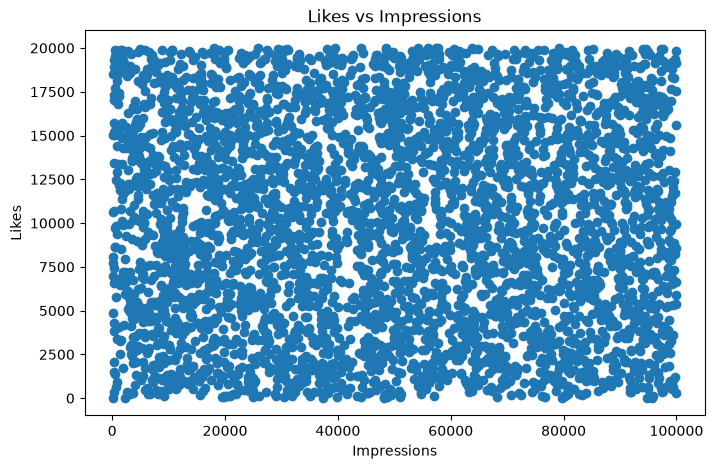

In [104]:
plt.figure(figsize=(8,5))

plt.scatter(df['impression_count'], df['likes'])

plt.xlabel("Impressions")
plt.ylabel("Likes")
plt.title("Likes vs Impressions")

plt.show()

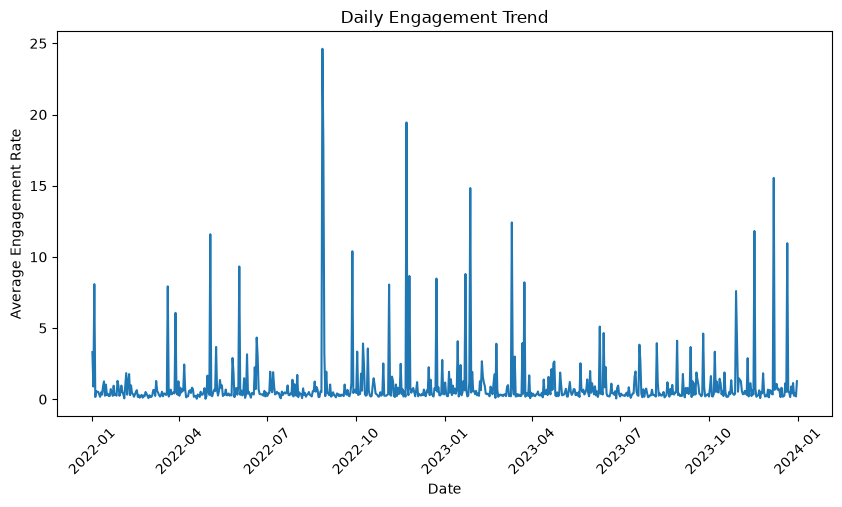

In [72]:
df['posted_at'] = pd.to_datetime(df['posted_at'])

daily_engagement = df.groupby(df['posted_at'].dt.date)['engagement_rate'].mean()

plt.figure(figsize=(10,5))

plt.plot(daily_engagement.index, daily_engagement.values)

plt.xlabel("Date")
plt.ylabel("Average Engagement Rate")
plt.title("Daily Engagement Trend")

plt.xticks(rotation=45)
plt.show()

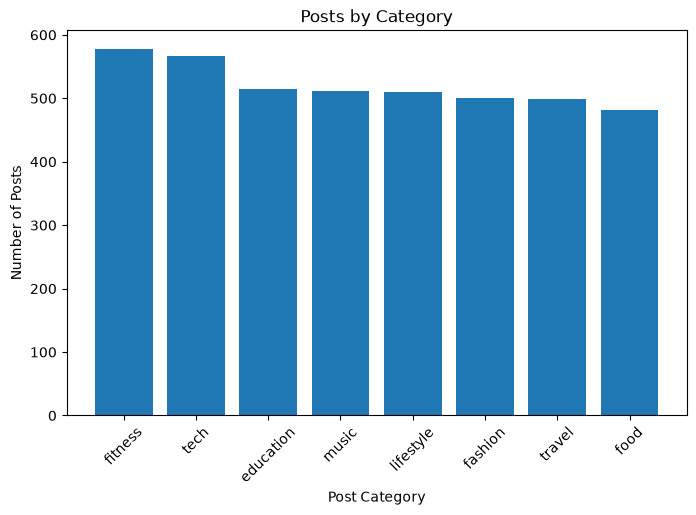

In [73]:
category_count = df['post_category'].value_counts()

plt.figure(figsize=(8,5))

plt.bar(category_count.index, category_count.values)

plt.xlabel("Post Category")
plt.ylabel("Number of Posts")
plt.title("Posts by Category")

plt.xticks(rotation=45)
plt.show()

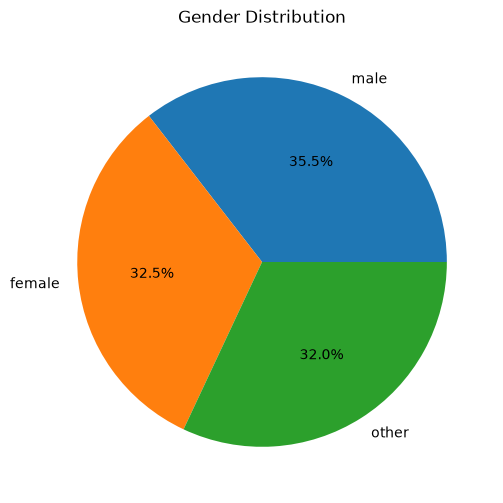

In [74]:
gender_count = df['gender'].value_counts()

plt.figure(figsize=(6,6))

plt.pie(gender_count, labels=gender_count.index, autopct='%1.1f%%')

plt.title("Gender Distribution")

plt.show()

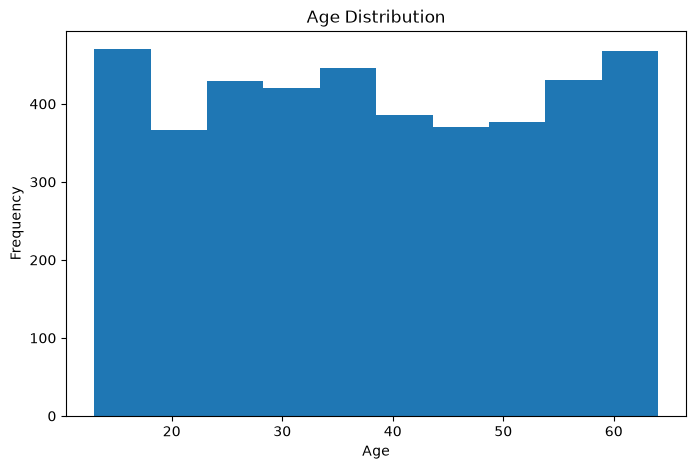

In [75]:
plt.figure(figsize=(8,5))

plt.hist(df['age'], bins=10)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Age Distribution")

plt.show()

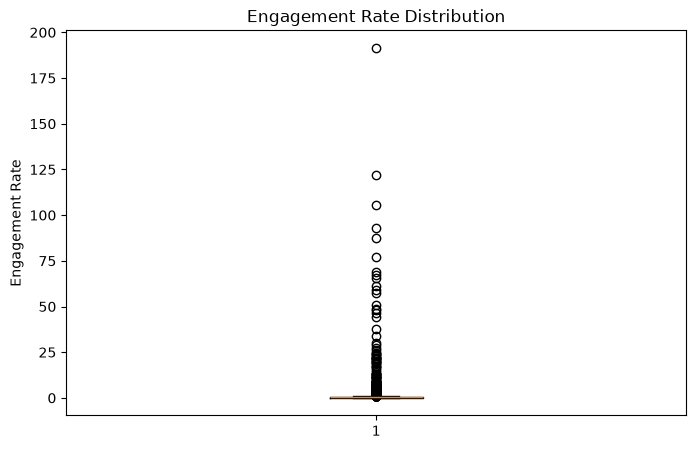

In [76]:
plt.figure(figsize=(8,5))

plt.boxplot(df['engagement_rate'])

plt.ylabel("Engagement Rate")
plt.title("Engagement Rate Distribution")

plt.show()

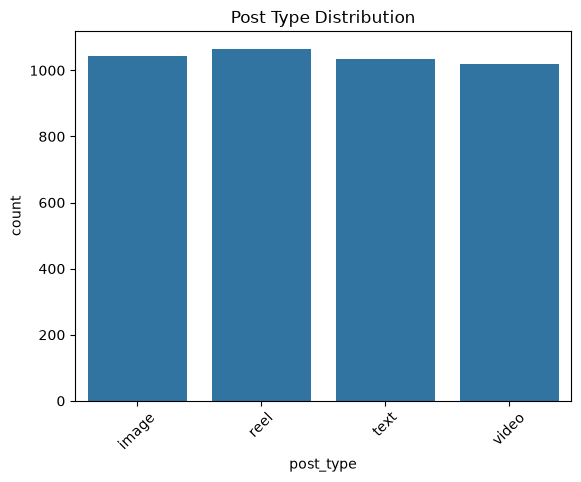

In [77]:
sns.countplot(data=df, x='post_type')

plt.title("Post Type Distribution")
plt.xticks(rotation=45)
plt.show()

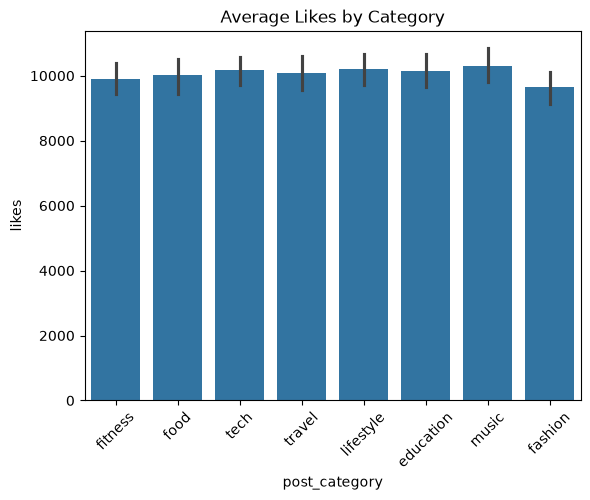

In [78]:
sns.barplot(data=df, x='post_category', y='likes')

plt.title("Average Likes by Category")
plt.xticks(rotation=45)
plt.show()

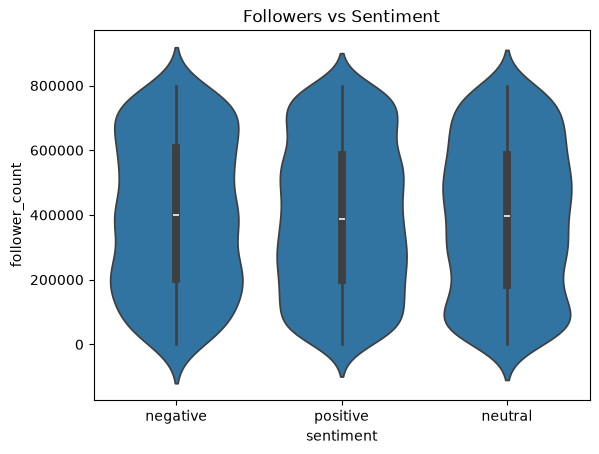

In [79]:
sns.violinplot(data=df, x='sentiment', y='follower_count')

plt.title("Followers vs Sentiment")
plt.show()

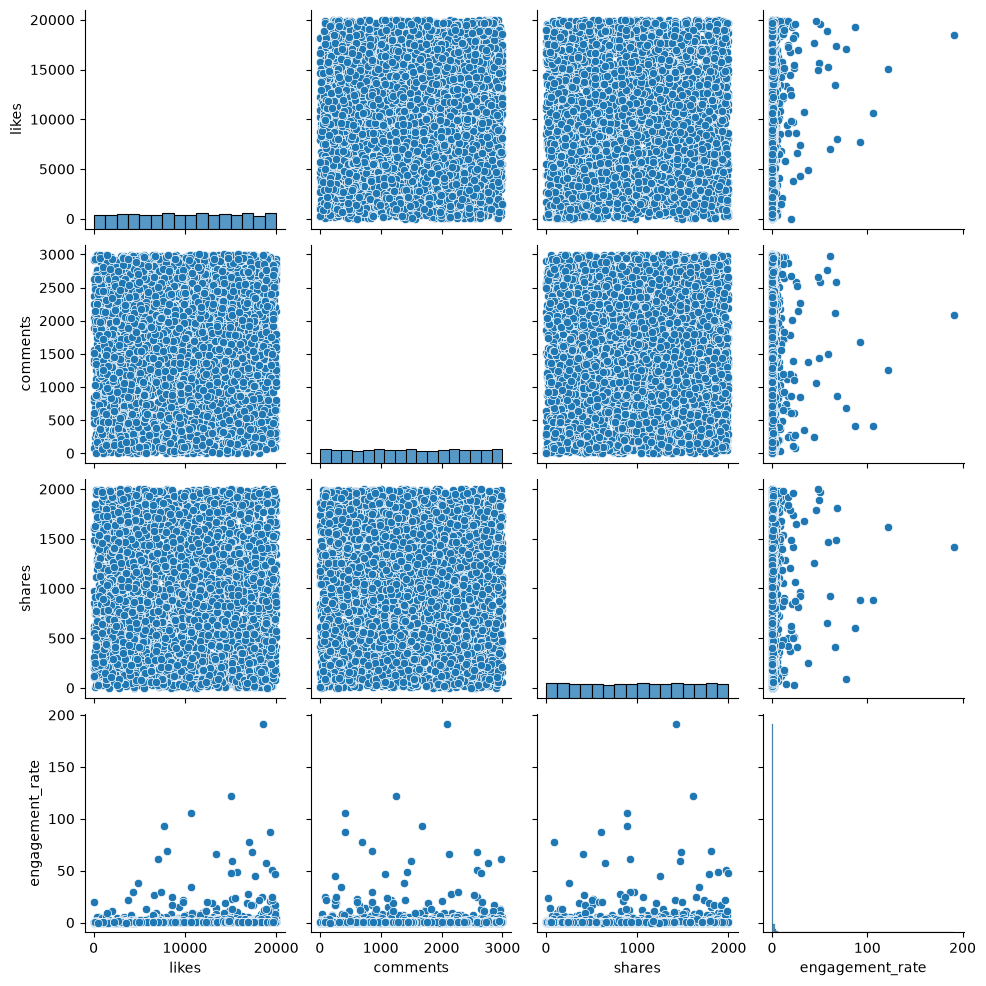

In [80]:
sns.pairplot(df[['likes', 'comments', 'shares', 'engagement_rate']])

plt.show()

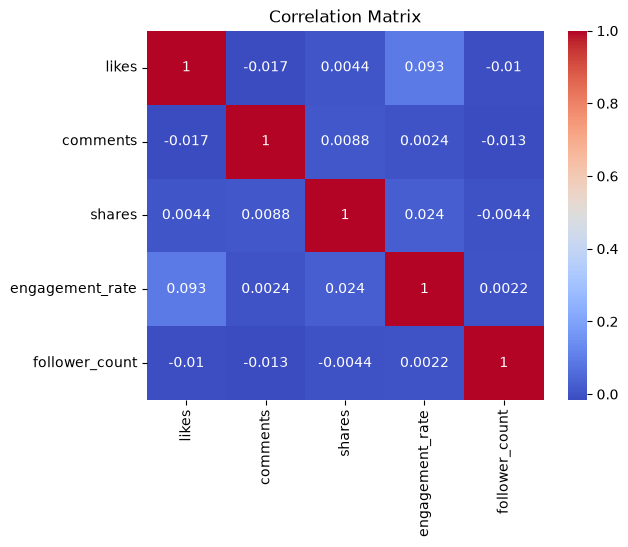

In [81]:
numeric_data = df[['likes', 'comments', 'shares', 'engagement_rate', 'follower_count']]

sns.heatmap(numeric_data.corr(), annot=True, cmap='coolwarm')

plt.title("Correlation Matrix")
plt.show()

c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 94.7% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 95.0% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 94.6% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, UserWarning)
c:\Users\user\AppData\Local\Programs\Python\Python313\Lib\site-packages\seaborn\categorical.py:3399: UserWarning: 95.2% of the points cannot be placed; you may want to decrease the size of the markers or use stripplot.
  warnings.warn(msg, U

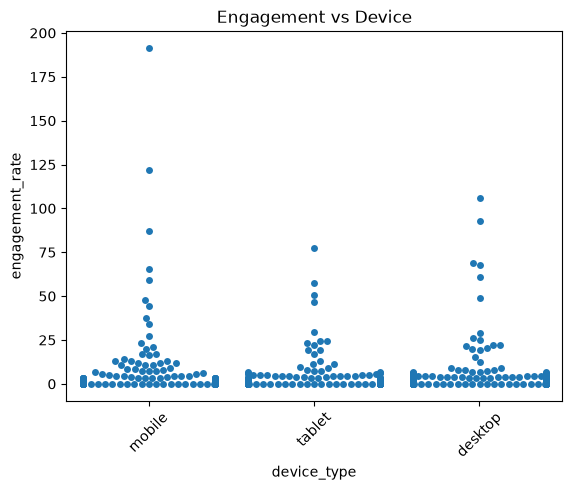

In [82]:
sns.swarmplot(data=df, x='device_type', y='engagement_rate')

plt.title("Engagement vs Device")
plt.xticks(rotation=45)
plt.show()

In [83]:
import plotly.express as px

In [84]:
daily_engagement_df = daily_engagement.reset_index()

daily_engagement_df.columns = ['date', 'engagement_rate']

In [103]:
fig = px.line(
    daily_engagement_df,
    x='date',
    y='engagement_rate',
    title='Interactive Daily Engagement Trend'
)

fig.show(renderer='browser')

In [93]:
post_type_engagement = df.groupby('post_type')['engagement_rate'].mean()

print(post_type_engagement)

post_type
image    0.912476
reel     0.794192
text     1.174698
video    1.189408
Name: engagement_rate, dtype: float64


Video posts have the highest average engagement rate (1.189), followed by text posts (1.175). Reel posts have the lowest average engagement rate (0.794).

In [94]:
category_engagement = df.groupby('post_category')['engagement_rate'].mean().sort_values(ascending=False)

print(category_engagement)

post_category
food         1.520192
tech         1.241241
lifestyle    1.197237
music        0.921123
education    0.853855
fashion      0.838359
fitness      0.834591
travel       0.734028
Name: engagement_rate, dtype: float64


Food is the best-performing content category, with the highest average engagement rate of 1.520. Tech and Lifestyle are the next highest-performing categories.

In [95]:
country_engagement = df.groupby('country')['engagement_rate'].mean().sort_values(ascending=False)

print(country_engagement)

country
Brazil       1.637193
Australia    1.462492
France       1.250086
UAE          1.116916
Canada       0.927467
UK           0.872840
Germany      0.817767
Japan        0.794976
India        0.690853
USA          0.549766
Name: engagement_rate, dtype: float64


Brazil has the highest average engagement rate at 1.637, followed by Australia at 1.462. India has an average engagement rate of 0.691 in this dataset.

In [96]:
age_engagement = df.groupby('age')['engagement_rate'].mean()

print(age_engagement)

age
13.0    0.392961
14.0    0.906557
15.0    0.615770
16.0    1.317706
17.0    0.887007
18.0    0.916630
19.0    0.741502
20.0    0.544490
21.0    0.474721
22.0    0.599418
23.0    1.096253
24.0    3.215180
25.0    1.107037
26.0    0.482576
27.0    0.697633
28.0    0.367257
29.0    1.219397
30.0    1.256742
31.0    0.479383
32.0    0.624722
33.0    0.952606
34.0    0.586922
35.0    1.683151
36.0    0.650738
37.0    0.502463
38.0    1.387125
39.0    0.459425
40.0    0.889688
41.0    1.566123
42.0    1.298485
43.0    0.536050
44.0    0.883221
45.0    0.543086
46.0    0.716516
47.0    1.620683
48.0    1.803907
49.0    1.102482
50.0    1.405301
51.0    2.742855
52.0    0.902690
53.0    0.807282
54.0    1.109595
55.0    2.891827
56.0    0.505857
57.0    0.863974
58.0    0.457344
59.0    0.435240
60.0    0.844274
61.0    0.580235
62.0    1.104579
63.0    1.355122
64.0    0.376993
Name: engagement_rate, dtype: float64


Engagement rate varies across different age groups, with no consistent increasing or decreasing trend. Some age groups, such as age 24, show notably higher average engagement.

In [97]:
verified_engagement = df.groupby('is_verified')['engagement_rate'].mean()

print(verified_engagement)

is_verified
False    1.001748
True     1.135869
Name: engagement_rate, dtype: float64


Verified accounts have a higher average engagement rate (1.136) compared with non-verified accounts (1.002).

In [98]:
df['hour'] = df['posted_at'].dt.hour

In [99]:
hour_impressions = df.groupby('hour')['impression_count'].mean().sort_values(ascending=False)

print(hour_impressions)

hour
0    50050.542528
Name: impression_count, dtype: float64


Best time of day for impressions could not be determined because the dataset does not contain valid time-of-day information in the posted_at column.

In [100]:
device_watch = df.groupby('device_type')['watch_time_sec'].mean().sort_values(ascending=False)

print(device_watch)

device_type
mobile     4017.509943
desktop    3975.406456
tablet     3970.761323
Name: watch_time_sec, dtype: float64


Mobile users have the highest average watch time (4017.51 seconds), followed by desktop (3975.41 seconds) and tablet users (3970.76 seconds).

In [101]:
sentiment_engagement = df.groupby('sentiment')['engagement_rate'].mean().sort_values(ascending=False)

print(sentiment_engagement)

sentiment
neutral     1.055031
negative    1.005130
positive    0.993237
Name: engagement_rate, dtype: float64


Neutral sentiment posts have the highest average engagement rate (1.055), followed by negative sentiment (1.005) and positive sentiment (0.993).

In [102]:
sentiment_behavior = df[df['sentiment'].isin(['negative', 'neutral'])].groupby('sentiment')[
    ['likes', 'comments', 'shares', 'engagement_rate']
].mean()

print(sentiment_behavior)

                  likes     comments      shares  engagement_rate
sentiment                                                        
negative   10116.993954  1519.695284  997.540508         1.005130
neutral     9937.506454  1531.094153  990.652240         1.055031


Negative sentiment posts received slightly higher average likes and shares than neutral posts, while neutral posts received slightly more comments. Neutral posts also had a higher average engagement rate (1.055) compared with negative posts (1.005).

### Final Insights

The analysis showed that **video posts** had the highest average engagement rate (1.189), while **food content** was the best-performing category (1.520). **Brazil** had the highest average engagement rate (1.637).

Engagement varied across age groups, with no consistent age-based trend. **Verified accounts** had higher average engagement (1.136) than non-verified accounts (1.002). **Mobile users** had the highest average watch time (4017.51 seconds).

Among sentiments, **neutral posts** had the highest average engagement rate (1.055). Negative posts received slightly more likes and shares, while neutral posts received more comments. The best time of day for impressions could not be determined because valid time information was not available in the dataset.

Overall, the analysis identified differences in engagement based on **post type, content category, country, verification status, device type, and sentiment**.
